# 05 · Kuantum çekirdeği (QM/QM/MM) ve ML2
*Makale: Bölüm 2.3–2.4, Denklem 7; Şekil 2 mor kutu ("with Traditional or Quantum Computer").*

DFT'nin hatası sistematik olarak düzeltilemiyor. Makale bu yüzden QM bölgesinin içinde daha küçük bir
**kuantum çekirdeği** tanımlıyor ve onu dalga fonksiyonu yöntemleriyle çözüyor:

- **CASCI(n, m):** Seçilen $m$ orbitalde $n$ elektron için Schrödinger denkleminin **tam** çözümü.
  Hilbert uzayı üstel büyüdüğü için klasik bilgisayarı zorlayan kısım bu. **Gelecekte bu kısmı kuantum
  bilgisayar (QPE) yapacak.**
- **NEVPT2:** Aktif uzay dışındaki "dinamik" korelasyonu ekleyen klasik pertürbasyon düzeltmesi.

Bizim misafirimiz küçük olduğu için kuantum çekirdeği bütün misafirden oluşuyor ve aktif uzay CAS(4,4).
Makalede ise çekirdek Ru d-orbitalleri; orada DFT içine Huzinaga gömmesi kullanılıyor.

**ML2 (transfer öğrenme):** Yüksek seviye hesap çok pahalı olduğu için **az** sayıda yapıda yapılıyor.
ML2, ML1'in üzerine yalnızca *farkı* öğreniyor:
$$\Delta U^\text{yüksek}_\text{etk}(x) \approx \text{ML1}(x) + \text{ML2}(x),\qquad \text{ML2} \leftarrow \Delta U_\text{etk}^\text{CASCI+NEVPT2} - \Delta U_\text{etk}^\text{DFT}$$

Yani ML2, kuantum çekirdeği seviyesinin misafir–çevre etkileşimini DFT'den ne kadar farklı gördüğünü öğreniyor.
Her etiket için hem gömülü hem vakum yüksek seviye hesabı yapılıyor.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
from qfe import config, store
from qfe.plotting import C, LEG, LEG_TR
import numpy as np, matplotlib.pyplot as plt
# Ön ayar: "test" (hızlı kontrol), "demo" (ekibe gösterim), "standart" (daha güvenilir)
config.set_preset(os.environ.get("QFE_PRESET", "demo"))
print("Aktif ön ayar:", config.preset_name())

Aktif ön ayar: test


In [2]:
from qfe import qmmm, ml
from pyscf import lib
lib.num_threads(os.cpu_count())
pools = {leg: (lambda d: (d["X"], d["B"]))(store.load_npz(f"pool_{leg}.npz")) for leg in ["complex", "solvent"]}
regions = {leg: qmmm.QMRegion(leg) for leg in pools}
lab = qmmm.Labeler(regions, pools)
lab.load_dict(store.load_json("labels.json"))
feats = {leg: ml.descriptors(regions[leg], *pools[leg]) for leg in pools}
ml1 = store.load_json("ml1.json")
train1 = [tuple(t) for t in ml1["train"]]
model1 = ml.GPModel().fit(np.array([feats[l][i] for l, i in train1]), np.array([lab.dU_dft(l, i) for l, i in train1]))
print("ML1 yeniden kuruldu,", len(train1), "eğitim noktası")

ML1 yeniden kuruldu, 20 eğitim noktası


### Tek bir yapıda seviyeleri karşılaştıralım

In [3]:
leg, i = train1[0]
fr = regions[leg].frame(pools[leg][0][i], pools[leg][1][i])
with store.timed("05_tek_yuksek_seviye"):
    h, mf, mc = qmmm.energy_high(fr, regions[leg].guest_symbols(), return_objects=True)
print(f"HF           : {h['e_hf']:.6f} Ha")
print(f"CASCI{tuple(config.P()['cas'])} : {h['e_casci']:.6f} Ha   (statik korelasyon {1000*(h['e_casci']-h['e_hf']):.3f} mHa)")
print(f"+ NEVPT2     : {h['e_total']:.6f} Ha   (dinamik korelasyon {1000*h['e_nevpt2_corr']:.1f} mHa)")
occ = mf.mo_occ; nocc = int((occ > 0).sum()); ncas = config.P()["cas"][0]
print(f"Aktif orbitaller: HOMO-{ncas//2-1} … LUMO+{ncas//2-1}, enerjiler (Ha):",
      np.round(mf.mo_energy[nocc-ncas//2:nocc+ncas//2], 3))

[süre] 05_tek_yuksek_seviye: 6.0 s
HF           : -269.826683 Ha
CASCI(4, 4) : -269.826744 Ha   (statik korelasyon -0.061 mHa)
+ NEVPT2     : -270.734631 Ha   (dinamik korelasyon -907.9 mHa)
Aktif orbitaller: HOMO-1 … LUMO+1, enerjiler (Ha): [-0.467 -0.434  0.155  0.191]


**Gözlem:** Siklopentanol kapalı kabuklu, "kolay" bir molekül. Statik korelasyon (CASCI − HF)
çok küçük, enerjinin büyük kısmı dinamik korelasyondan geliyor. Bu, makaledeki **Şekil 1'in sol alt
köşesi**. Bu tür sistemlerde kuantum avantajı beklenmiyor. Makalenin Ru kompleksi ise açık kabuklu
(spin dubleti) ve çok referanslı, yani kuantum bilgisayarın asıl fark yaratacağı türden bir sistem.
Burada amacımız avantaj göstermek değil, **iş akışının nasıl kurulduğunu** göstermek.

### ML2 eğitim verisi

In [4]:
p = config.P()
rng = np.random.default_rng(2)
# ML2 yapıları havuzdan RASTGELE seçilir. ML1'in eğitim kümesi aktif öğrenmeyle seçilmiş uç yapılardan
# oluştuğu için oradan seçmek ML2'yi havuzun tipik yapılarına göre yanlı yapar.
ml2_set = []
for leg in pools:
    n = len(pools[leg][0])
    sel = rng.choice(n, size=min(n, p["ml2_points"] // 2), replace=False)
    ml2_set += [(leg, int(i)) for i in sel]
with store.timed("05_yuksek_seviye_etiketler") as rec:
    delta = np.array([lab.high_minus_dft(l, i) for l, i in ml2_set])
    rec["n"] = len(ml2_set)
store.save_json("labels.json", lab.to_dict())
store.save_json("ml2.json", {"train": ml2_set})
print(f"{len(ml2_set)} yapı, ortalama yüksek seviye süresi (gömülü + vakum) {np.mean(lab.timings['high']):.1f} s")
print(f"δ = ΔU_etk(yüksek) − ΔU_etk(DFT): ortalama {delta.mean():+.2f}, std {delta.std():.2f} kJ/mol")

[süre] 05_yuksek_seviye_etiketler: 72.3 s
6 yapı, ortalama yüksek seviye süresi (gömülü + vakum) 12.0 s
δ = ΔU_etk(yüksek) − ΔU_etk(DFT): ortalama -3.25, std 1.25 kJ/mol


ΔΔG(MM→QM/QM/MM) [Zwanzig  ] =  -2.06 ± 1.00  →  ΔG(MM+ML2) = -34.01 kJ/mol
ΔΔG(MM→QM/QM/MM) [kümülant ] =  -0.55 ± 0.70  →  ΔG(MM+ML2) = -32.50 kJ/mol


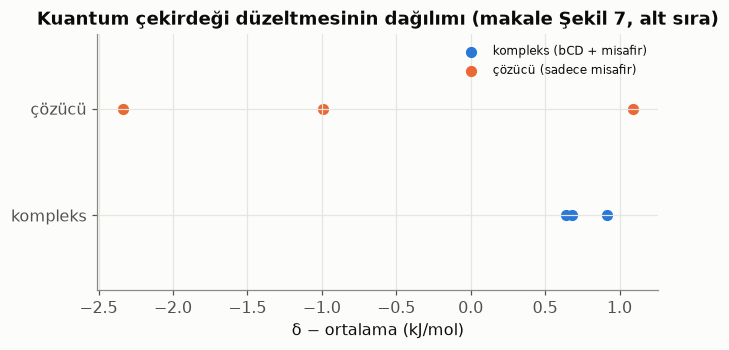

In [5]:
model2 = ml.GPModel(seed=1).fit(np.array([feats[l][i] for l, i in ml2_set]), delta)
dU_ml2 = {leg: model1.predict(feats[leg]) + model2.predict(feats[leg]) for leg in pools}
corr2 = ml.binding_correction(dU_ml2["complex"], dU_ml2["solvent"])
r = store.load_json("results.json")
dG_mm, err_mm = r["dG_MM"]["dG_bind"], r["dG_MM"]["dG_bind_err"]
for key, name in [("exp", "Zwanzig"), ("cumulant", "kümülant")]:
    print(f"ΔΔG(MM→QM/QM/MM) [{name:9s}] = {corr2[key]:+6.2f} ± {corr2[key+'_err']:.2f}  →  "
          f"ΔG(MM+ML2) = {dG_mm + corr2[key]:6.2f} kJ/mol")
store.save_json("results.json", {"corr_ML2": corr2, "dG_MM_ML2": dG_mm + corr2["cumulant"],
                                 "dG_MM_ML2_err": float(np.hypot(err_mm, corr2["cumulant_err"]))})
fig, ax = plt.subplots(figsize=(6.2, 3.3))
for leg in pools:
    m = np.array([l == leg for l, _ in ml2_set])
    ax.scatter(delta[m] - delta.mean(), np.full(m.sum(), 0 if leg == "complex" else 1), color=LEG[leg], s=40, label=LEG_TR[leg])
ax.set_yticks([0, 1], ["kompleks", "çözücü"]); ax.set_ylim(-0.7, 1.7)
ax.set_xlabel("δ − ortalama (kJ/mol)")
ax.set_title("Kuantum çekirdeği düzeltmesinin dağılımı (makale Şekil 7, alt sıra)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Dikkat:** Makalede en kritik nokta, δ'nın dağılımının **dar** olması (Şekil 7, alt sıra). Dar olduğunda
ML2 onu az veriyle öğrenebiliyor. Makale bunun için ~10.000 QM/QM/MM enerjisi kullanıyor; bunlar
gelecekte kuantum bilgisayardan gelecek. Bir sonraki notebook'ta bu enerjilerin kuantum algoritmasıyla
nasıl hesaplanacağını simüle ediyoruz.